# CA1 Machine Learning
### Ciaran Lynch sba26096

Predicting Football Over 2.5 goals per game from the English Premier League from 2020/2021 season to 2025/26
Using Machine Learning Classification Models

In [207]:
import pandas as pd
import seaborn as sns
%matplotlib inline  
import matplotlib.pyplot as plt
import numpy as np

## Data Preparation

The goal at Data Preparation stage is to import the 6 csv files for The six Premier League years from 2020/2021 to 2025/26, into a dataframe
The Dataframes will be called:
df_PL_2020 = 2020/21 season
df_PL2021 = 2021/22 season
df_PL2022 = 2022/23 season
df_PL_2023 = 2023/24 season
df_PL2024 = 2024/25 season
df_PL_2025 = 2025/26 season  

source: https://football-data.co.uk/data.php  

This is a publicly available repository containing the required historical match statistics.  
    
The data held within the csv files include important match data, such as, goals scored, shots on target, home goals, away goals and match results.  
    
These variables will be relevant to the proposed business problem as they provide the information required for machine learning models to identify patterns associated with predicting football match outcomes.  
    
The data will be used solely for research and academic purposes in accordance with the website’s own restrictions.

## Create a Function to: 
Read the original csv files
Keep only required columns
Rename columns to make it more readable
Create new columns for Half Time Goals and Full Time Goals
Create a Dictionary to replace League name from the csv files

In [208]:
def prepare_league(file_name): # file_name is a parameter given to the function
    
    # read in csv
    df = pd.read_csv(file_name)
    
    # rename columns
    df = df.rename(columns={
    "Div": "League",
    "HomeTeam": "Home_Team",
    "AwayTeam": "Away_Team",
    "FTHG": "FT_Home_Goals",
    "FTAG": "FT_Away_Goals",
    "FTR": "Result",
    "HTHG": "HT_Home_Goals",
    "HTAG": "HT_Away_Goals",
    "HST": "Home_Shots_On_Target",
    "AST": "Away_Shots_On_Target",
    "HC": "Home_Corners",
    "AC": "Away_Corners",

    } 
    )
    
    # create duplicate dataframe with required columns only
    df = df[
        ["Date", 
          "League", 
          "Home_Team", 
          "Away_Team", 
          "HT_Home_Goals",
          "HT_Away_Goals", 
          "FT_Home_Goals", 
          "FT_Away_Goals", 
          "Home_Shots_On_Target",
          "Away_Shots_On_Target",
          "Home_Corners",
          "Away_Corners"]
          ].copy()
    
    # create new columns for half time and full time goals
    df["HT_Goals"] = (
    df["HT_Home_Goals"] + df["HT_Away_Goals"] 
    )

    df["FT_Goals"] = (
    df["FT_Home_Goals"] + df["FT_Away_Goals"] 
    )

    # create new columns for Total Shots on Target
    df["Total_Shots_On_Target"] = (
    df["Home_Shots_On_Target"] + df["Away_Shots_On_Target"] 
    )

    # create new columns for Total Corners
    df["Total_Corners"] = (
    df["Home_Corners"] + df["Away_Corners"] 
    )
    # Create a Dictionary to replace League names from the csv files.  This will make it more readable once i created a merged dataframe
    df["League"] = df["League"].replace( 
        {
            "E0": "English Premier League",
        }

   
    )
            

    return df
    


Call the Premier League 2020/2021 using the prepare league function
Run Data Preparation

In [209]:
df_PL_2020 = prepare_league("Premier_League_2020_2021.csv") 

In [210]:
df_PL_2020.head(5)

,Date,League,Home_Team,Away_Team,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
0,12/09/2020,English Premier League,Fulham,Arsenal,0,1,0,3,2,6,2,3,1,3,8,5
1,12/09/2020,English Premier League,Crystal Palace,Southampton,1,0,1,0,3,5,7,3,1,1,8,10
2,12/09/2020,English Premier League,Liverpool,Leeds,3,2,4,3,6,3,9,0,5,7,9,9
3,12/09/2020,English Premier League,West Ham,Newcastle,0,0,0,2,3,2,8,7,0,2,5,15
4,13/09/2020,English Premier League,West Brom,Leicester,0,0,0,3,1,7,2,5,0,3,8,7


In [211]:
df_PL_2020.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Date                   380 non-null    object
 1   League                 380 non-null    object
 2   Home_Team              380 non-null    object
 3   Away_Team              380 non-null    object
 4   HT_Home_Goals          380 non-null    int64 
 5   HT_Away_Goals          380 non-null    int64 
 6   FT_Home_Goals          380 non-null    int64 
 7   FT_Away_Goals          380 non-null    int64 
 8   Home_Shots_On_Target   380 non-null    int64 
 9   Away_Shots_On_Target   380 non-null    int64 
 10  Home_Corners           380 non-null    int64 
 11  Away_Corners           380 non-null    int64 
 12  HT_Goals               380 non-null    int64 
 13  FT_Goals               380 non-null    int64 
 14  Total_Shots_On_Target  380 non-null    int64 
 15  Total_Corners          

In [212]:
print(df_PL_2020.shape)

(380, 16)


In [213]:
df_PL_2020.isnull().sum()

Date                     0
League                   0
Home_Team                0
Away_Team                0
HT_Home_Goals            0
HT_Away_Goals            0
FT_Home_Goals            0
FT_Away_Goals            0
Home_Shots_On_Target     0
Away_Shots_On_Target     0
Home_Corners             0
Away_Corners             0
HT_Goals                 0
FT_Goals                 0
Total_Shots_On_Target    0
Total_Corners            0
dtype: int64

No Missing values with the Premier League 2020_2021

Call the Premier League 2021/2022 using the prepare league function
Run Data Preparation

In [214]:
df_PL_2021 = prepare_league("Premier_League_2021_2022.csv") 

In [215]:
df_PL_2021.head(5)

,Date,League,Home_Team,Away_Team,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
0,13/08/2021,English Premier League,Brentford,Arsenal,1,0,2,0,3,4,2,5,1,2,7,7
1,14/08/2021,English Premier League,Man United,Leeds,1,0,5,1,8,3,5,4,1,6,11,9
2,14/08/2021,English Premier League,Burnley,Brighton,1,0,1,2,3,8,7,6,1,3,11,13
3,14/08/2021,English Premier League,Chelsea,Crystal Palace,2,0,3,0,6,1,5,2,2,3,7,7
4,14/08/2021,English Premier League,Everton,Southampton,0,1,3,1,6,3,6,8,1,4,9,14


In [216]:
df_PL_2021.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Date                   380 non-null    object
 1   League                 380 non-null    object
 2   Home_Team              380 non-null    object
 3   Away_Team              380 non-null    object
 4   HT_Home_Goals          380 non-null    int64 
 5   HT_Away_Goals          380 non-null    int64 
 6   FT_Home_Goals          380 non-null    int64 
 7   FT_Away_Goals          380 non-null    int64 
 8   Home_Shots_On_Target   380 non-null    int64 
 9   Away_Shots_On_Target   380 non-null    int64 
 10  Home_Corners           380 non-null    int64 
 11  Away_Corners           380 non-null    int64 
 12  HT_Goals               380 non-null    int64 
 13  FT_Goals               380 non-null    int64 
 14  Total_Shots_On_Target  380 non-null    int64 
 15  Total_Corners          

In [217]:
print(df_PL_2021.shape)

(380, 16)


In [218]:
df_PL_2021.isnull().sum()

Date                     0
League                   0
Home_Team                0
Away_Team                0
HT_Home_Goals            0
HT_Away_Goals            0
FT_Home_Goals            0
FT_Away_Goals            0
Home_Shots_On_Target     0
Away_Shots_On_Target     0
Home_Corners             0
Away_Corners             0
HT_Goals                 0
FT_Goals                 0
Total_Shots_On_Target    0
Total_Corners            0
dtype: int64

No Missing values with the Premier League 2021_2022

Call the Premier League 2022/2023 using the prepare league function
Run Data Preparation

In [219]:
df_PL_2022 = prepare_league("Premier_League_2022_2023.csv") 

In [220]:
df_PL_2022.head(5)

,Date,League,Home_Team,Away_Team,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
0,05/08/2022,English Premier League,Crystal Palace,Arsenal,0,1,0,2,2,2,3,5,1,2,4,8
1,06/08/2022,English Premier League,Fulham,Liverpool,1,0,2,2,3,4,4,4,1,4,7,8
2,06/08/2022,English Premier League,Bournemouth,Aston Villa,1,0,2,0,3,2,5,5,1,2,5,10
3,06/08/2022,English Premier League,Leeds,Wolves,1,1,2,1,4,6,6,4,2,3,10,10
4,06/08/2022,English Premier League,Newcastle,Nott'm Forest,0,0,2,0,10,0,11,1,0,2,10,12


In [221]:
df_PL_2022.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Date                   380 non-null    object
 1   League                 380 non-null    object
 2   Home_Team              380 non-null    object
 3   Away_Team              380 non-null    object
 4   HT_Home_Goals          380 non-null    int64 
 5   HT_Away_Goals          380 non-null    int64 
 6   FT_Home_Goals          380 non-null    int64 
 7   FT_Away_Goals          380 non-null    int64 
 8   Home_Shots_On_Target   380 non-null    int64 
 9   Away_Shots_On_Target   380 non-null    int64 
 10  Home_Corners           380 non-null    int64 
 11  Away_Corners           380 non-null    int64 
 12  HT_Goals               380 non-null    int64 
 13  FT_Goals               380 non-null    int64 
 14  Total_Shots_On_Target  380 non-null    int64 
 15  Total_Corners          

In [222]:
print(df_PL_2022.shape)

(380, 16)


In [223]:
df_PL_2022.isnull().sum()

Date                     0
League                   0
Home_Team                0
Away_Team                0
HT_Home_Goals            0
HT_Away_Goals            0
FT_Home_Goals            0
FT_Away_Goals            0
Home_Shots_On_Target     0
Away_Shots_On_Target     0
Home_Corners             0
Away_Corners             0
HT_Goals                 0
FT_Goals                 0
Total_Shots_On_Target    0
Total_Corners            0
dtype: int64

No Missing values with the Premier League 2022_2023

Call the Premier League 2023/2024 using the prepare league function
Run Data Preparation

In [224]:
df_PL_2023 = prepare_league("Premier_League_2023_2024.csv") 

In [225]:
df_PL_2023.head(5)

,Date,League,Home_Team,Away_Team,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
0,11/08/2023,English Premier League,Burnley,Man City,0,2,0,3,1,8,6,5,2,3,9,11
1,12/08/2023,English Premier League,Arsenal,Nott'm Forest,2,0,2,1,7,2,8,3,2,3,9,11
2,12/08/2023,English Premier League,Bournemouth,West Ham,0,0,1,1,5,3,10,4,0,2,8,14
3,12/08/2023,English Premier League,Brighton,Luton,1,0,4,1,12,3,6,7,1,5,15,13
4,12/08/2023,English Premier League,Everton,Fulham,0,0,0,1,9,2,10,4,0,1,11,14


In [226]:
df_PL_2023.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Date                   380 non-null    object
 1   League                 380 non-null    object
 2   Home_Team              380 non-null    object
 3   Away_Team              380 non-null    object
 4   HT_Home_Goals          380 non-null    int64 
 5   HT_Away_Goals          380 non-null    int64 
 6   FT_Home_Goals          380 non-null    int64 
 7   FT_Away_Goals          380 non-null    int64 
 8   Home_Shots_On_Target   380 non-null    int64 
 9   Away_Shots_On_Target   380 non-null    int64 
 10  Home_Corners           380 non-null    int64 
 11  Away_Corners           380 non-null    int64 
 12  HT_Goals               380 non-null    int64 
 13  FT_Goals               380 non-null    int64 
 14  Total_Shots_On_Target  380 non-null    int64 
 15  Total_Corners          

In [227]:
print(df_PL_2023.shape)

(380, 16)


In [228]:
df_PL_2023.isnull().sum()

Date                     0
League                   0
Home_Team                0
Away_Team                0
HT_Home_Goals            0
HT_Away_Goals            0
FT_Home_Goals            0
FT_Away_Goals            0
Home_Shots_On_Target     0
Away_Shots_On_Target     0
Home_Corners             0
Away_Corners             0
HT_Goals                 0
FT_Goals                 0
Total_Shots_On_Target    0
Total_Corners            0
dtype: int64

No Missing values with the Premier League 2020_2021

Call the Premier League 2024/2025 using the prepare league function
Run Data Preparation

In [229]:
df_PL_2024 = prepare_league("Premier_League_2024_2025.csv") 

In [230]:
df_PL_2024.head(5)

,Date,League,Home_Team,Away_Team,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
0,16/08/2024,English Premier League,Man United,Fulham,0,0,1,0,5,2,7,8,0,1,7,15
1,17/08/2024,English Premier League,Ipswich,Liverpool,0,0,0,2,2,5,2,10,0,2,7,12
2,17/08/2024,English Premier League,Arsenal,Wolves,1,0,2,0,6,3,8,2,1,2,9,10
3,17/08/2024,English Premier League,Everton,Brighton,0,1,0,3,1,5,1,5,1,3,6,6
4,17/08/2024,English Premier League,Newcastle,Southampton,1,0,1,0,1,4,3,12,1,1,5,15


In [231]:
df_PL_2024.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Date                   380 non-null    object
 1   League                 380 non-null    object
 2   Home_Team              380 non-null    object
 3   Away_Team              380 non-null    object
 4   HT_Home_Goals          380 non-null    int64 
 5   HT_Away_Goals          380 non-null    int64 
 6   FT_Home_Goals          380 non-null    int64 
 7   FT_Away_Goals          380 non-null    int64 
 8   Home_Shots_On_Target   380 non-null    int64 
 9   Away_Shots_On_Target   380 non-null    int64 
 10  Home_Corners           380 non-null    int64 
 11  Away_Corners           380 non-null    int64 
 12  HT_Goals               380 non-null    int64 
 13  FT_Goals               380 non-null    int64 
 14  Total_Shots_On_Target  380 non-null    int64 
 15  Total_Corners          

In [232]:
print(df_PL_2024.shape)

(380, 16)


In [233]:
df_PL_2024.isnull().sum()

Date                     0
League                   0
Home_Team                0
Away_Team                0
HT_Home_Goals            0
HT_Away_Goals            0
FT_Home_Goals            0
FT_Away_Goals            0
Home_Shots_On_Target     0
Away_Shots_On_Target     0
Home_Corners             0
Away_Corners             0
HT_Goals                 0
FT_Goals                 0
Total_Shots_On_Target    0
Total_Corners            0
dtype: int64

No Missing values with the Premier League 2024_2025

Call the Premier League 2025/2026 using the prepare league function
Run Data Preparation

In [234]:
df_PL_2025 = prepare_league("Premier_League_2025_2026.csv") 

In [235]:
df_PL_2025.head(5)

,Date,League,Home_Team,Away_Team,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
0,15/08/2025,English Premier League,Liverpool,Bournemouth,1,0,4,2,10,3,6,7,1,6,13,13
1,16/08/2025,English Premier League,Aston Villa,Newcastle,0,0,0,0,3,3,3,6,0,0,6,9
2,16/08/2025,English Premier League,Brighton,Fulham,0,0,1,1,4,2,4,3,0,2,6,7
3,16/08/2025,English Premier League,Sunderland,West Ham,0,0,3,0,5,4,5,7,0,3,9,12
4,16/08/2025,English Premier League,Tottenham,Burnley,1,0,3,0,6,4,6,5,1,3,10,11


In [236]:
df_PL_2025.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 380 entries, 0 to 379
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Date                   380 non-null    object
 1   League                 380 non-null    object
 2   Home_Team              380 non-null    object
 3   Away_Team              380 non-null    object
 4   HT_Home_Goals          380 non-null    int64 
 5   HT_Away_Goals          380 non-null    int64 
 6   FT_Home_Goals          380 non-null    int64 
 7   FT_Away_Goals          380 non-null    int64 
 8   Home_Shots_On_Target   380 non-null    int64 
 9   Away_Shots_On_Target   380 non-null    int64 
 10  Home_Corners           380 non-null    int64 
 11  Away_Corners           380 non-null    int64 
 12  HT_Goals               380 non-null    int64 
 13  FT_Goals               380 non-null    int64 
 14  Total_Shots_On_Target  380 non-null    int64 
 15  Total_Corners          

In [237]:
print(df_PL_2025.shape)

(380, 16)


In [238]:
df_PL_2025.isnull().sum()

Date                     0
League                   0
Home_Team                0
Away_Team                0
HT_Home_Goals            0
HT_Away_Goals            0
FT_Home_Goals            0
FT_Away_Goals            0
Home_Shots_On_Target     0
Away_Shots_On_Target     0
Home_Corners             0
Away_Corners             0
HT_Goals                 0
FT_Goals                 0
Total_Shots_On_Target    0
Total_Corners            0
dtype: int64

No Missing values with the Premier League 2025_2026

## Create an Integrated Football Dataset

Concat all dataFrames into 1 Master File

How to guide was used following the pandas documentation:  
https://pandas.pydata.org/pandas-docs/stable/user_guide/merging.html


In [239]:
frames = [df_PL_2020, df_PL_2021, df_PL_2022, df_PL_2023, df_PL_2024, df_PL_2025]

In [240]:
df_PL_Master = pd.concat(frames,ignore_index=True) 

## Run Data Preparation

In [241]:
df_PL_Master.sample(10)

,Date,League,Home_Team,Away_Team,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
1752,01/02/2025,English Premier League,Ipswich,Southampton,1,1,1,2,6,4,1,2,2,3,10,3
1163,26/08/2023,English Premier League,Everton,Wolves,0,0,0,1,7,2,7,0,0,1,9,7
2188,04/03/2026,English Premier League,Man City,Nott'm Forest,1,0,2,2,7,4,6,1,1,4,11,7
2037,03/12/2025,English Premier League,Leeds,Chelsea,2,0,3,1,5,2,4,2,2,4,7,6
2158,11/02/2026,English Premier League,Sunderland,Liverpool,0,0,0,1,2,3,3,11,0,1,5,14
1643,30/11/2024,English Premier League,Nott'm Forest,Ipswich,0,0,1,0,5,3,8,7,0,1,8,15
2093,03/01/2026,English Premier League,Bournemouth,Arsenal,1,1,2,3,3,5,7,5,2,5,8,12
528,06/12/2021,English Premier League,Everton,Arsenal,0,1,2,1,5,3,3,3,1,3,8,6
1173,02/09/2023,English Premier League,Chelsea,Nott'm Forest,0,0,0,1,2,3,8,0,0,1,5,8
2056,14/12/2025,English Premier League,Sunderland,Newcastle,0,0,1,0,1,2,3,6,0,1,3,9


In [242]:
df_PL_Master.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2280 entries, 0 to 2279
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Date                   2280 non-null   object
 1   League                 2280 non-null   object
 2   Home_Team              2280 non-null   object
 3   Away_Team              2280 non-null   object
 4   HT_Home_Goals          2280 non-null   int64 
 5   HT_Away_Goals          2280 non-null   int64 
 6   FT_Home_Goals          2280 non-null   int64 
 7   FT_Away_Goals          2280 non-null   int64 
 8   Home_Shots_On_Target   2280 non-null   int64 
 9   Away_Shots_On_Target   2280 non-null   int64 
 10  Home_Corners           2280 non-null   int64 
 11  Away_Corners           2280 non-null   int64 
 12  HT_Goals               2280 non-null   int64 
 13  FT_Goals               2280 non-null   int64 
 14  Total_Shots_On_Target  2280 non-null   int64 
 15  Total_Corners        

In [243]:
print(df_PL_Master.shape)

(2280, 16)


In [244]:
df_PL_Master.isnull().sum()

Date                     0
League                   0
Home_Team                0
Away_Team                0
HT_Home_Goals            0
HT_Away_Goals            0
FT_Home_Goals            0
FT_Away_Goals            0
Home_Shots_On_Target     0
Away_Shots_On_Target     0
Home_Corners             0
Away_Corners             0
HT_Goals                 0
FT_Goals                 0
Total_Shots_On_Target    0
Total_Corners            0
dtype: int64

All CSV files sucessfully looaded
Master file created by merging all csv files
No missing values on the data

### Check Home_Team and Away_Team columns in case of duplicate naming, ie Nottm Forest being also listed as Nottingham Forest

In [245]:
sorted(df_PL_Master["Home_Team"].unique() )

['Arsenal',
 'Aston Villa',
 'Bournemouth',
 'Brentford',
 'Brighton',
 'Burnley',
 'Chelsea',
 'Crystal Palace',
 'Everton',
 'Fulham',
 'Ipswich',
 'Leeds',
 'Leicester',
 'Liverpool',
 'Luton',
 'Man City',
 'Man United',
 'Newcastle',
 'Norwich',
 "Nott'm Forest",
 'Sheffield United',
 'Southampton',
 'Sunderland',
 'Tottenham',
 'Watford',
 'West Brom',
 'West Ham',
 'Wolves']

In [246]:
sorted(df_PL_Master["Away_Team"].unique() )

['Arsenal',
 'Aston Villa',
 'Bournemouth',
 'Brentford',
 'Brighton',
 'Burnley',
 'Chelsea',
 'Crystal Palace',
 'Everton',
 'Fulham',
 'Ipswich',
 'Leeds',
 'Leicester',
 'Liverpool',
 'Luton',
 'Man City',
 'Man United',
 'Newcastle',
 'Norwich',
 "Nott'm Forest",
 'Sheffield United',
 'Southampton',
 'Sunderland',
 'Tottenham',
 'Watford',
 'West Brom',
 'West Ham',
 'Wolves']

No unusual naming of the same team, all data is correct funder Home and Away team names

Check for any Duplicate rows

In [247]:
duplicateRows = df_PL_Master[df_PL_Master.duplicated()]
print("The number of duplicate rows = ", len(duplicateRows))

The number of duplicate rows =  0


## Exploratory Data Analysis

### Descriptive Statistics

In [248]:
df_PL_Master.describe()

,HT_Home_Goals,HT_Away_Goals,FT_Home_Goals,FT_Away_Goals,Home_Shots_On_Target,Away_Shots_On_Target,Home_Corners,Away_Corners,HT_Goals,FT_Goals,Total_Shots_On_Target,Total_Corners
count,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000,2280.000000
mean,0.714474,0.582018,1.556579,1.331579,4.817544,4.114912,5.623684,4.685088,1.296491,2.888158,8.932456,10.308772
std,0.845483,0.793972,1.321291,1.213014,2.574566,2.354860,3.056375,2.820496,1.115838,1.680552,3.097763,3.394148
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2.000000
25%,0.000000,0.000000,1.000000,0.000000,3.000000,2.000000,3.000000,3.000000,0.000000,2.000000,7.000000,8.000000
50%,1.000000,0.000000,1.000000,1.000000,5.000000,4.000000,5.000000,4.000000,1.000000,3.000000,9.000000,10.000000
75%,1.000000,1.000000,2.000000,2.000000,6.000000,5.000000,8.000000,6.000000,2.000000,4.000000,11.000000,13.000000
max,5.000000,5.000000,9.000000,8.000000,16.000000,15.000000,17.000000,19.000000,7.000000,9.000000,21.000000,24.000000


## Target Variable Distribution
### The Target Variable will be Over 2.5 goals
#### Find the results of over 2.5

In [249]:
df_PL_Master["Over_2.5"] = np.where(df_PL_Master["FT_Goals"] > 2, 1,0)

print(df_PL_Master["Over_2.5"].value_counts() )

Over_2.5
1    1265
0    1015
Name: count, dtype: int64


## Show the over 2.5 Goals as a Bar Chart

<Axes: xlabel='Over_2.5', ylabel='count'>

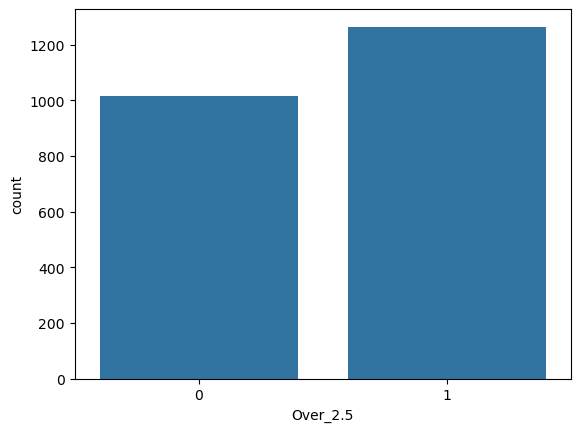

In [250]:
sns.countplot(
    data=df_PL_Master,
    x="Over_2.5"
)

#### The target variable shows a balanced class distribution 
#### 1265 Over 2.5
#### 1015 under 2.5
#### This should reduce any risk of model bias towards a dominant class

## Create a Boxplot to show Over 2.5

<Axes: xlabel='Over_2.5', ylabel='Total_Shots_On_Target'>

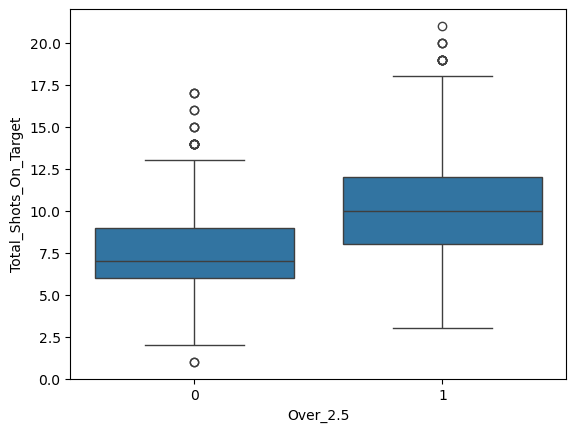

In [251]:
sns.boxplot(
    data=df_PL_Master,
    x="Over_2.5",
    y="Total_Shots_On_Target"
)

Analysis of the above Boxplot, suggests that more shots on target tend to have a higher correlation to over 2.5 goals (1)

## Create a Correlation heatmap

In [252]:
df_Corr = df_PL_Master[
    ["Over_2.5",
     "Total_Corners", 
     "Total_Shots_On_Target", 
     "HT_Home_Goals", 
     "HT_Away_Goals", 
     "HT_Goals", 
     "Home_Shots_On_Target", 
     "Away_Shots_On_Target",
     "Home_Corners",
     "Away_Corners"
    ] 
    ].corr()

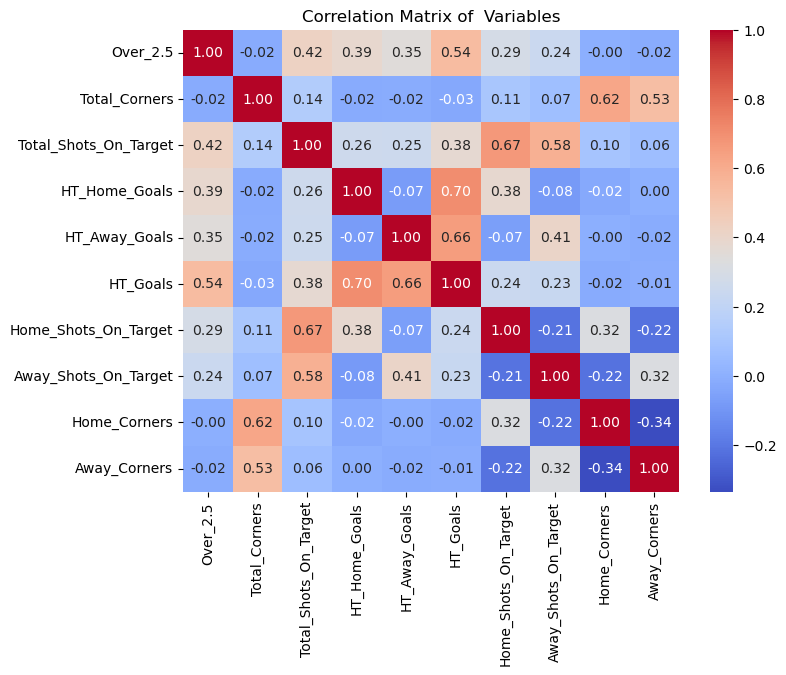

In [253]:
# create a seaborn heatmap
plt.figure(figsize=(8,6) )

sns.heatmap(
    df_Corr,  
    annot=True,   
    cmap="coolwarm",  
    fmt=".2f" )      

plt.title("Correlation Matrix of  Variables")

plt.show()

The above heatmap shows strong correlation to Over 2.5 Goals from:

Half Time Goals 0.54   
Half Time Home Goals 0.39   
Half Time Away Goals 0.35   
Total Shots on Target 0.42  

Half Time goals  0.54 indicates that first half goals are likely to finish with over 2.5 goals at the end of the game  

However, surprisingly the number of corners does not have a positive correlation to over 2.5 goals


#### Create a Histogram of Total Goals

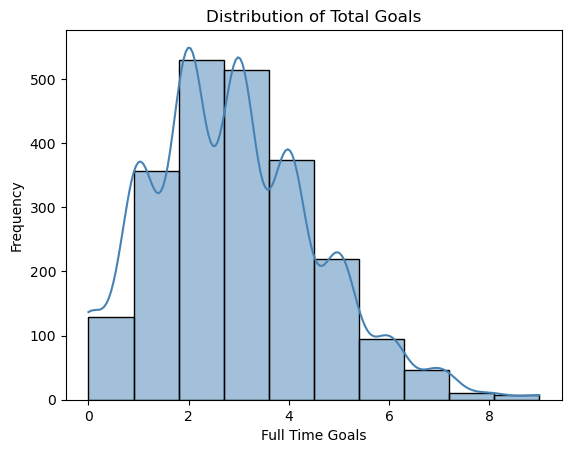

In [254]:
sns.histplot(
    data=df_PL_Master,
    x="FT_Goals", 
    bins=10,
    kde=True,
    color="Steelblue"
)

plt.title("Distribution of Total Goals")
plt.xlabel("Full Time Goals")
plt.ylabel("Frequency")
plt.show()


The distribution of total goals is positively skewed

Most matches produce 1-4 goals per game

Matches with more than 6 goals are relatively rare

The histogram demonstrates that the target variable of over 2.5 goals is appropriate for classification


Check Normality (using Shapiro_Wilk_test)

In [255]:
from scipy import stats 
from scipy.stats import norm # for normality test 

In [256]:
stat, p_value = stats.shapiro(df_PL_Master["FT_Goals"])

print(stat,p_value)

0.9495699788214029 2.6349078228629415e-27


In [257]:
if p_value >= 0.05:
    print("Sample appears to be normally distributed.")
else:
    print("Sample does not appear to be normally distributed.")
    

Sample does not appear to be normally distributed.


Create a GroupBy analysis of Half Time goals, Total Shots on Target and Total Corners against the Over 2.5 Outcome

#### GroupBy Results

In [258]:
df_PL_Master.groupby("Over_2.5")[
        ["HT_Goals",
         "Total_Shots_On_Target",
        "Total_Corners"]
    ].mean()

,HT_Goals,Total_Shots_On_Target,Total_Corners
Over_2.5,,,
0,0.622660,7.464039,10.374384
1,1.837154,10.110672,10.256126


Half Time Goals Analysis  

Matches that finished under 2.5 goals, had an average of 0.64 half time goals  

Whereas matches that finished over 2.5, had an average of 1.84 half time goals  

Indicating that half time goals may be a good indicator of higher scoring games

Shots on Target Analysis  

Matches with over 2.5 goals showed a higher shots on target 10.11 than the 7.46 for under 2.5  

This also indicates a positive relationship between attacking play and over 2.5 goals  

This also aligns with the heatmap correlation of 0.42

Total Corners Analysis

Total Corners had approximately 10 for both over 2.5 and under 2.5.  This suggests little influence between the number of corners and goals per game

#### Exploratory Data Analysis -  Conclusion

The analysis has identified that half time goals along with shots on target have a higher correlation to games ending in more than 2.5 goals.  
In contrast the corners statistics showed little correlation, indicating that attacking action seems to be a more useful predictor overall

In [259]:
# df_PL_Master.to_csv("Premier League Master.csv", index=False)

#### Classification Model Testing

The Target variable was created earlier as a binary classification, where 3 or more golas =1, else =0

Import sklearn libraries

In [260]:
df_PL_Master.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2280 entries, 0 to 2279
Data columns (total 17 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Date                   2280 non-null   object
 1   League                 2280 non-null   object
 2   Home_Team              2280 non-null   object
 3   Away_Team              2280 non-null   object
 4   HT_Home_Goals          2280 non-null   int64 
 5   HT_Away_Goals          2280 non-null   int64 
 6   FT_Home_Goals          2280 non-null   int64 
 7   FT_Away_Goals          2280 non-null   int64 
 8   Home_Shots_On_Target   2280 non-null   int64 
 9   Away_Shots_On_Target   2280 non-null   int64 
 10  Home_Corners           2280 non-null   int64 
 11  Away_Corners           2280 non-null   int64 
 12  HT_Goals               2280 non-null   int64 
 13  FT_Goals               2280 non-null   int64 
 14  Total_Shots_On_Target  2280 non-null   int64 
 15  Total_Corners        

In [261]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report

Run the model prior to PCA

In [262]:
No_Columns = df_PL_Master.shape[1]
print (f"The original number of columns is : {No_Columns}")

The original number of columns is : 17


I now need to split the dataset into the independent and dependent variables.  
I also need to bring forward only the numeric values from the original dataset.  
To prevent data leakage, it is important to remove any values that will provide the actual results, such as Over_2.5 variable itself, Full time goals, Full time home goals and Full time away goals.  

The dependent Y Target is "Over 2.5" column
    

In [263]:
# Spliting the dataset into independent and dependent variables

# Use numeric variables only from the daatasett
X = df_PL_Master.select_dtypes(include=[np.number])

# Remove the target_code and other associated columns that give the goals scored, to prevent data leakage
X = X.drop(columns=[
     "Over_2.5",
     "FT_Home_Goals",
     "FT_Away_Goals",
     "FT_Goals"
    ])


# Dependent variables (Target)
y = df_PL_Master["Over_2.5"]

num_rows = X.shape[0]
num_features = X.shape[1]

print(f" The number of rows: {num_rows} ")
print(f" The number of numeric features selected was: {num_features} ")



 The number of rows: 2280 
 The number of numeric features selected was: 9 


Run a 5% Test Split

In [264]:
# Splitting the dataset into the Training set and Test set

# test _size = 0.05 = 5%, random_state =82, is an arbitory number set throughout the tests
# Split the dataset (X, y) into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size = 0.05, 
    random_state = 82,
    stratify=y
    )

# Display rows and columns
X_train.shape, X_test.shape

((2166, 9), (114, 9))

In [265]:
# Feature Scaling to bring the variable in a single scale


# Create an initialise an object sc by calling a method StandardScaler()
sc = StandardScaler()

# Train the model by calling a method fit_transform
X_train = sc.fit_transform(X_train)

# Store the transformed data into X_test
X_test = sc.transform(X_test)

In [266]:
# NB = Naive Bayes
# Gaussian = assumes the numeric variables follow a normal distribution

# Create an initialise an object "nb_model" by calling a method 'GaussianNB()'
nb_model = GaussianNB()

# Call fit() method for training the dataset
nb_model.fit(
    X_train,
    y_train)

,priors,None
,var_smoothing,1e-09


In [267]:
# Predicting the Test set results
y_pred = nb_model.predict(
    X_test)

In [268]:
# Check the actual and predicted value side by side
y_compare = np.vstack((y_test,y_pred)).T
# actual value on the left side and predicted value on the right hand side
# printing the top 20 values
y_compare[:20,:]

array([[0, 0],
       [1, 0],
       [0, 0],
       [0, 0],
       [1, 1],
       [0, 1],
       [1, 1],
       [0, 0],
       [0, 0],
       [0, 0],
       [1, 1],
       [0, 0],
       [1, 0],
       [0, 0],
       [0, 1],
       [0, 0],
       [0, 0],
       [1, 0],
       [0, 0],
       [1, 1]])

In [269]:
score = accuracy_score(
    y_test, 
    y_pred)


print(f"Accuray Score for a 5% Test split is : {score:.2%} ")

Accuray Score for a 5% Test split is : 81.58% 


In [270]:
print(classification_report(
    y_test,
    y_pred)
)

              precision    recall  f1-score   support

           0       0.73      0.92      0.82        51
           1       0.92      0.73      0.81        63

    accuracy                           0.82       114
   macro avg       0.83      0.83      0.82       114
weighted avg       0.84      0.82      0.82       114



Run a 15% Test Split

In [271]:
# Splitting the dataset into the Training set and Test set


# Split the dataset (X, y) into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size = 0.15, 
    random_state = 82,
    stratify=y
    )

# Display rows and columns
X_train.shape, X_test.shape

((1938, 9), (342, 9))

In [272]:
# Feature Scaling to bring the variable in a single scale


# Create an initialise an object sc by calling a method StandardScaler()
sc = StandardScaler()

# Train the model by calling a method fit_transform
X_train = sc.fit_transform(X_train)

# Store the transformed data into X_test
X_test = sc.transform(X_test)

In [273]:
# NB = Naive Bayes
# Gaussian = assumes the numeric variables follow a normal distribution

# Create an initialise an object "nb_model" by calling a method 'GaussianNB()'
nb_model = GaussianNB()

# Call fit() method for training the dataset
nb_model.fit(
    X_train,
    y_train)

,priors,None
,var_smoothing,1e-09


In [274]:
# Predicting the Test set results
y_pred = nb_model.predict(
    X_test)

In [275]:
# Check the actual and predicted value side by side
y_compare = np.vstack((y_test,y_pred)).T
# actual value on the left side and predicted value on the right hand side
# printing the top 20 values
y_compare[:20,:]

array([[0, 1],
       [1, 1],
       [0, 0],
       [1, 1],
       [0, 0],
       [0, 0],
       [1, 1],
       [1, 1],
       [1, 1],
       [1, 0],
       [0, 0],
       [0, 0],
       [0, 0],
       [1, 0],
       [1, 1],
       [1, 1],
       [1, 1],
       [0, 0],
       [1, 1],
       [0, 1]])

In [276]:
score = accuracy_score(
    y_test, 
    y_pred)


print(f"Accuray Score for a 15% Test split is : {score:.2%} ")

Accuray Score for a 15% Test split is : 79.24% 


In [277]:
print(classification_report(
    y_test,
    y_pred)
)

              precision    recall  f1-score   support

           0       0.73      0.85      0.78       152
           1       0.86      0.75      0.80       190

    accuracy                           0.79       342
   macro avg       0.79      0.80      0.79       342
weighted avg       0.80      0.79      0.79       342



Run a 25% Test Split

In [278]:
# Splitting the dataset into the Training set and Test set


# Split the dataset (X, y) into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size = 0.25, 
    random_state = 82,
    stratify=y
    )

# Display rows and columns
X_train.shape, X_test.shape

((1710, 9), (570, 9))

In [279]:
# Feature Scaling to bring the variable in a single scale


# Create an initialise an object sc by calling a method StandardScaler()
sc = StandardScaler()

# Train the model by calling a method fit_transform
X_train = sc.fit_transform(X_train)

# Store the transformed data into X_test
X_test = sc.transform(X_test)

In [280]:
# NB = Naive Bayes
# Gaussian = assumes the numeric variables follow a normal distribution

# Create an initialise an object "nb_model" by calling a method 'GaussianNB()'
nb_model = GaussianNB()

# Call fit() method for training the dataset
nb_model.fit(
    X_train,
    y_train)

,priors,None
,var_smoothing,1e-09


In [281]:
# Predicting the Test set results
y_pred = nb_model.predict(
    X_test)

In [282]:
# Check the actual and predicted value side by side
y_compare = np.vstack((y_test,y_pred)).T
# actual value on the left side and predicted value on the right hand side
# printing the top 20 values
y_compare[:20,:]

array([[1, 1],
       [0, 0],
       [0, 1],
       [1, 1],
       [0, 0],
       [1, 1],
       [0, 0],
       [0, 0],
       [0, 1],
       [0, 0],
       [1, 1],
       [0, 0],
       [0, 1],
       [0, 0],
       [0, 1],
       [0, 0],
       [0, 1],
       [1, 0],
       [1, 1],
       [1, 1]])

In [283]:
score = accuracy_score(
    y_test, 
    y_pred)


print(f"Accuray Score for a 25% Test split is : {score:.2%} ")

Accuray Score for a 25% Test split is : 76.49% 


In [284]:
print(classification_report(
    y_test,
    y_pred)
)

              precision    recall  f1-score   support

           0       0.70      0.83      0.76       254
           1       0.84      0.71      0.77       316

    accuracy                           0.76       570
   macro avg       0.77      0.77      0.76       570
weighted avg       0.78      0.76      0.77       570



### Classification Model Testing
The Target variable was defined as a binary classification problem, where matches finishing with more than 2.5 goals were assigned the value of 1, otherwise, the value of 0.  
    
    
A Gaussian Naive Bayes classifier was selected due to its effectiveness when working with numerical predictors.  

The dataset was split into (X) for the predictor variables and the Target variable was (y).  

Variables that contained match outcome results were removed to prevent data leakage.  


### Test Split evaluation

The train-test configurations consisted of 5%, 15% and 25% test datasets.  

Stratified sampling was applied (stratify=y) to maintain consistent class distribution between the training and testing datasets.  

Standardisation was performed only on the training data, to ensure that information from the test set was not introduced, avoiding data leakage.  

    

## Results Analysis
The Gaussian Naive Bayes model achieved an accuracy of:  

5% Test split = 81.58%  

15% Test split = 79.24%  

25% Test split = 76.49%

The results remained relatively consistent and the model performed well across unseen data, suggesting that it did not appear to suffer from any substantial overfitting


Run the Model after PCA  

25% Test Split is selected for PCA as it provides the largest test dataset

In [285]:
# Splitting the PCA  dataset into the Training set and Test set


# Split the dataset (X, y) into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y, 
    test_size = 0.25, 
    random_state = 82,
    stratify=y
    )
    

# Scale training data only
scaler = StandardScaler()


# Train the model by calling a method fit_transform
X_train_scaled = scaler.fit_transform(X_train)
# Store the transformed data into X_test
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=0.90) 

# Display rows and columns
X_train.shape, X_test.shape

# Train the model by calling a method fit_transform
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

In [286]:
# NB = Naive Bayes
# Gaussian = assumes the numeric variables follow a normal distribution

# Create an initialise an object "nb_model" by calling a method 'GaussianNB()'
nb_model = GaussianNB()

# Call fit() method for training the dataset
nb_model.fit(
    X_train_pca,
    y_train)

# Predicting the Test set results
y_pred = nb_model.predict(
    X_test_pca)

In [287]:
# Check the actual and predicted value side by side
y_compare = np.vstack((y_test,y_pred)).T
# actual value on the left side and predicted value on the right hand side
# printing the top 20 values
y_compare[:20,:]

array([[1, 1],
       [0, 0],
       [0, 1],
       [1, 1],
       [0, 0],
       [1, 1],
       [0, 0],
       [0, 0],
       [0, 1],
       [0, 0],
       [1, 1],
       [0, 0],
       [0, 1],
       [0, 0],
       [0, 1],
       [0, 0],
       [0, 1],
       [1, 0],
       [1, 1],
       [1, 1]])

In [288]:
score = accuracy_score(
    y_test, 
    y_pred)


print(f"The PCA Accuray Score is : {score:.2%} ")

The PCA Accuray Score is : 75.96% 


In [289]:
print(classification_report(
    y_test,
    y_pred)
)

              precision    recall  f1-score   support

           0       0.71      0.78      0.74       254
           1       0.81      0.74      0.77       316

    accuracy                           0.76       570
   macro avg       0.76      0.76      0.76       570
weighted avg       0.76      0.76      0.76       570



In [290]:
print(f"The number of columns in the original dataset was: {No_Columns} ")
print(f"The number of numeric columns in the dataset, prior to PCA was: {num_features} ")
print(f"The number of components retained after PCA was: {pca.n_components_} ")    
print(f"The percentage of Variance retained was: {pca.explained_variance_ratio_.sum()*100:.2f} %") 

The number of columns in the original dataset was: 17 
The number of numeric columns in the dataset, prior to PCA was: 9 
The number of components retained after PCA was: 5 
The percentage of Variance retained was: 94.63 %


### PCA Analysis
Principal Component Analysis (PCA) was the applied dimensionality reduction technique.  

In line with previous tests, it was kept at 25% test split, as this provided the largest sample.  

PCA was set to retain 90% of the total variance contained within the original dataset.  

Prior to PCA, the numeric columns used in the test split dataset was 9.  PCA reduced the total columns to 5, whilst still retaining 94.63% of the total variance.

The PCA model returned an accuracy score of 75.96%. This suggests that PCA was able to reduce the dataset and still produce comparable predictive performance.  
    
        

### Conclusion
Overall the results suggest that half time goals and shots on target  provide useful predictors for identifying the over 2.5 result.

PCA also demonstrated that dimensionality reduction can maintain comparable prediction perfomance.    